# Policy Evaluation

Compare a trained TRSP policy against the Dijkstra and DSP baselines on the 100 OD pairs from its latest evaluation run.

Set `policy_id` to any entry under `runs/trsp/`. Requires `simulation_results.csv`, `simulation_results_dijkstra.csv`, and `simulation_results_dsp.csv` to be co-located in the latest `test_N/` directory (produced automatically by `eval_trsp2.py`).

In [8]:
import re
import pandas as pd
import numpy as np
from pathlib import Path

# --- User config ---
policy_id = "9224a7b9"

# --- Helpers (prefixed _pe_ to avoid conflicts with later sections) ---
def _pe_latest_test_dir(policy_dir: Path) -> Path:
    tests = sorted(
        [p for p in policy_dir.glob("test_*") if p.is_dir()],
        key=lambda p: int(re.match(r"test_(\d+)$", p.name).group(1)),
    )
    if not tests:
        raise ValueError(f"No test_* dirs in {policy_dir}")
    return tests[-1]

def _pe_load_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["start_idx"]       = pd.to_numeric(df["start_idx"],       errors="coerce").astype("Int64")
    df["target_idx"]      = pd.to_numeric(df["target_idx"],      errors="coerce").astype("Int64")
    df["total_time_taken"] = pd.to_numeric(df["total_time_taken"], errors="coerce")
    return df

def _pe_is_success(df: pd.DataFrame) -> pd.Series:
    s = df["failed_error"].astype("string").str.strip().str.lower()
    return df["failed_error"].isna() | s.isin(["", "na", "nan", "none"])

_PE_KEY_COLS = ["start_idx", "target_idx"]
_PE_TIME_COL = "total_time_taken"
_PE_PATH_COL = "path_edges"

# --- Load ---
runs_root  = Path("../runs/trsp")
pe_test_dir = _pe_latest_test_dir(runs_root / policy_id)

df_pe_policy = _pe_load_csv(pe_test_dir / "simulation_results.csv")
df_pe_dij    = _pe_load_csv(pe_test_dir / "simulation_results_dijkstra.csv")
df_pe_dsp    = _pe_load_csv(pe_test_dir / "simulation_results_dsp.csv")

pe_labels   = [policy_id[:8], "dijkstra", "dsp"]
pe_dfs_raw  = [df_pe_policy, df_pe_dij, df_pe_dsp]

print(f"Test dir: {pe_test_dir}")
for lbl, df in zip(pe_labels, pe_dfs_raw):
    ok = _pe_is_success(df) & (df[_PE_TIME_COL] > 0)
    print(f"  {lbl:>12s}: {ok.sum()}/{len(df)} successful")

# --- Filter, deduplicate, intersect on all three ---
pe_dfs_succ = []
for df in pe_dfs_raw:
    ok = _pe_is_success(df) & (df[_PE_TIME_COL] > 0)
    d  = (df[ok]
          .sort_values(_PE_TIME_COL)
          .drop_duplicates(subset=_PE_KEY_COLS, keep="first")
          .reset_index(drop=True))
    pe_dfs_succ.append(d)

pair_sets       = [set(zip(d["start_idx"], d["target_idx"])) for d in pe_dfs_succ]
pe_common_pairs = pair_sets[0] & pair_sets[1] & pair_sets[2]

pe_dfs = []
for d in pe_dfs_succ:
    mask = d.apply(lambda r: (r["start_idx"], r["target_idx"]) in pe_common_pairs, axis=1)
    pe_dfs.append(d[mask].sort_values(_PE_KEY_COLS).reset_index(drop=True))

assert all(len(d) == len(pe_common_pairs) for d in pe_dfs), "Row count mismatch after intersect"

# --- Same-path time adjustment ---
for i in [1, 2]:
    p0   = pe_dfs[0][_PE_PATH_COL].astype("string").fillna("").str.strip()
    pi   = pe_dfs[i][_PE_PATH_COL].astype("string").fillna("").str.strip()
    same = p0 == pi
    shared = np.minimum(pe_dfs[0][_PE_TIME_COL].values, pe_dfs[i][_PE_TIME_COL].values)
    pe_dfs[0].loc[same, _PE_TIME_COL] = shared[same.values]
    pe_dfs[i].loc[same, _PE_TIME_COL] = shared[same.values]
p1, p2   = (pe_dfs[j][_PE_PATH_COL].astype("string").fillna("").str.strip() for j in [1, 2])
same_12  = p1 == p2
shared12 = np.minimum(pe_dfs[1][_PE_TIME_COL].values, pe_dfs[2][_PE_TIME_COL].values)
pe_dfs[1].loc[same_12, _PE_TIME_COL] = shared12[same_12.values]
pe_dfs[2].loc[same_12, _PE_TIME_COL] = shared12[same_12.values]

pe_route_key = pe_dfs[0]["start_idx"].astype(str) + "->" + pe_dfs[0]["target_idx"].astype(str)
for d in pe_dfs:
    d["route_index"] = np.arange(len(d))
    d["route_key"]   = pe_route_key.values

pe_times = [d[_PE_TIME_COL].values for d in pe_dfs]

# --- Summary ---
summary = pd.DataFrame([
    {"algorithm": lbl, "mean_time": t.mean(), "median_time": np.median(t),
     "min_time": t.min(), "max_time": t.max()}
    for lbl, t in zip(pe_labels, pe_times)
])
print(f"\nCommon successful OD pairs: {len(pe_common_pairs)}")
print("\nTime summary (same-path adjusted):")
display(summary)

Test dir: ../runs/trsp/9224a7b9/test_0
      9224a7b9: 99/100 successful
      dijkstra: 97/100 successful
           dsp: 99/100 successful

Common successful OD pairs: 95

Time summary (same-path adjusted):


,algorithm,mean_time,median_time,min_time,max_time
0,9224a7b9,107.736842,112.0,1.0,219.0
1,dijkstra,222.126316,185.0,1.0,668.0
2,dsp,122.400000,123.0,1.0,343.0


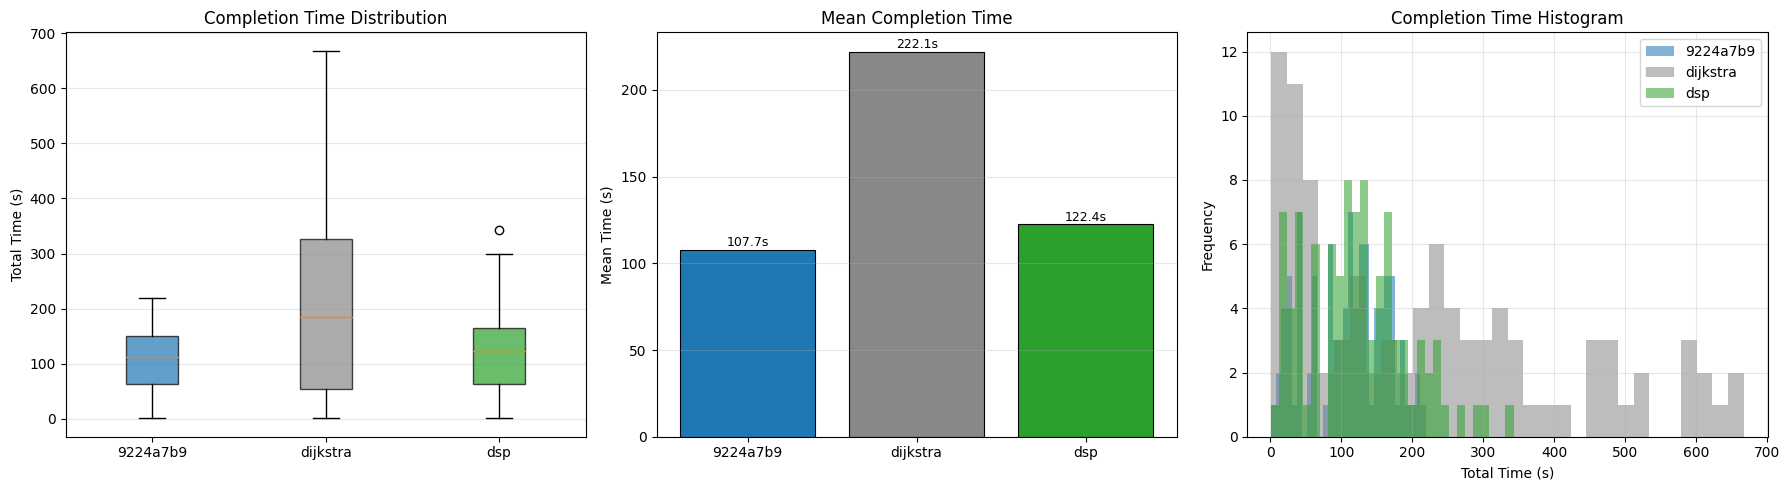

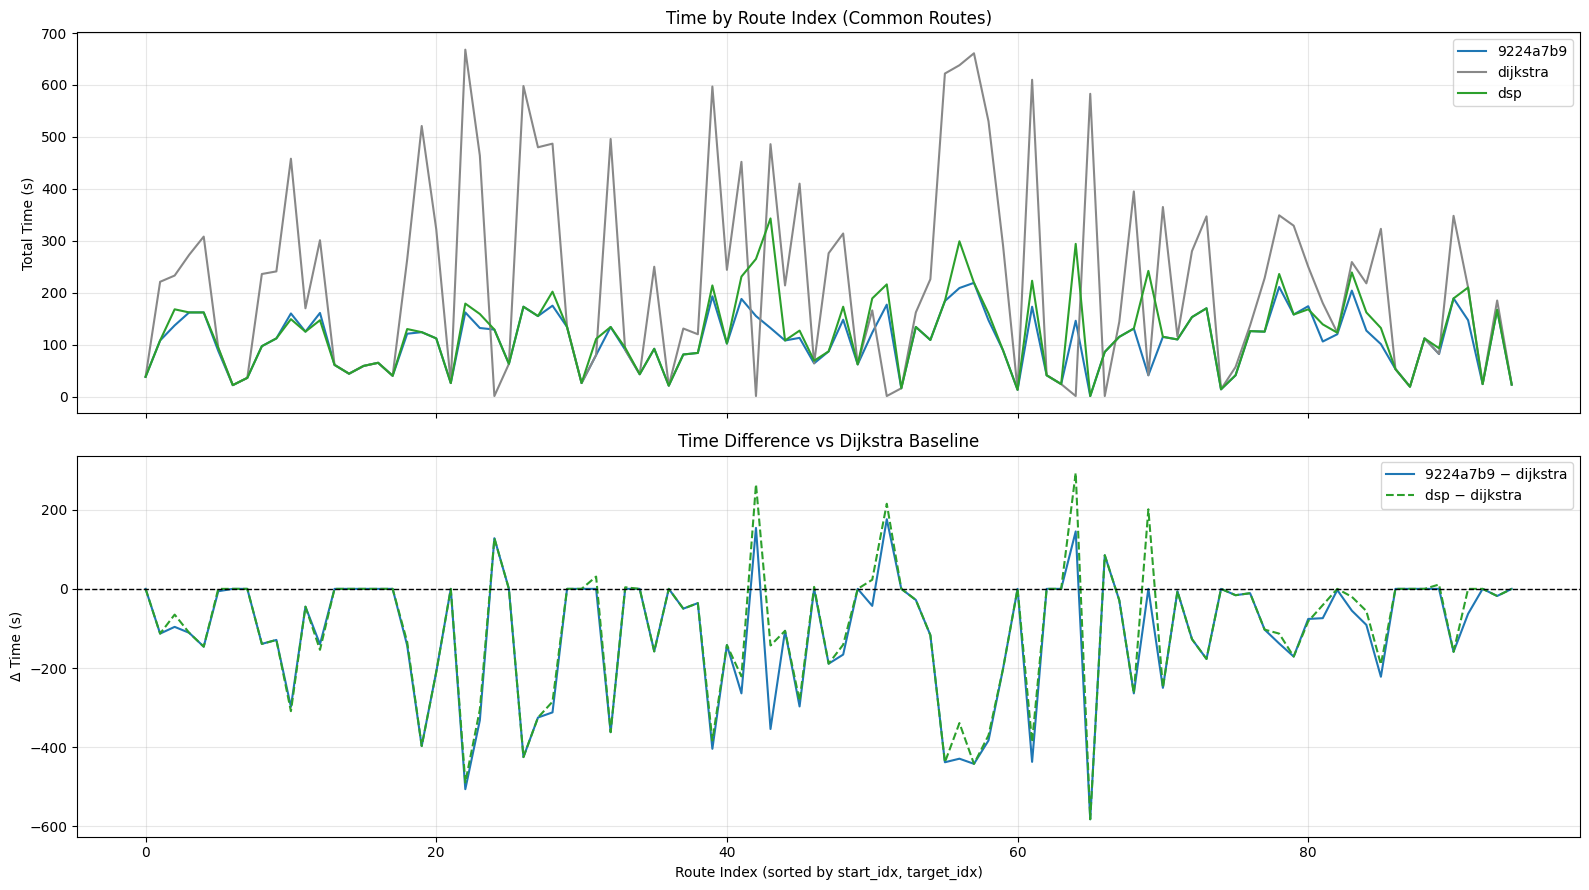

Mean time — 9224a7b9: 107.7s  |  dijkstra: 222.1s  |  dsp: 122.4s
9224a7b9 vs dijkstra: -114.4s avg,  60/95 routes faster
dsp vs dijkstra:  -99.7s avg,  56/95 routes faster


In [9]:
import matplotlib.pyplot as plt

_PE_COLORS = {
    pe_labels[0]: "#1f77b4",   # policy → blue
    "dijkstra":   "#888888",
    "dsp":        "#2ca02c",
}
pe_lbl_colors = [_PE_COLORS.get(l, "#1f77b4") for l in pe_labels]

# --- Box / mean bar / histogram ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bp = axes[0].boxplot(
    [d[_PE_TIME_COL].dropna().values for d in pe_dfs],
    labels=pe_labels, patch_artist=True,
)
for patch, color in zip(bp["boxes"], pe_lbl_colors):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[0].set_title("Completion Time Distribution")
axes[0].set_ylabel("Total Time (s)"); axes[0].grid(axis="y", alpha=0.3)

means = [t.mean() for t in pe_times]
bars = axes[1].bar(pe_labels, means, color=pe_lbl_colors, edgecolor="black", linewidth=0.8)
for bar, val in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width() / 2, val + 0.5, f"{val:.1f}s",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_title("Mean Completion Time")
axes[1].set_ylabel("Mean Time (s)"); axes[1].grid(axis="y", alpha=0.3)

for d, lbl, c in zip(pe_dfs, pe_labels, pe_lbl_colors):
    axes[2].hist(d[_PE_TIME_COL], bins=30, alpha=0.55, label=lbl, color=c)
axes[2].set_title("Completion Time Histogram")
axes[2].set_xlabel("Total Time (s)"); axes[2].set_ylabel("Frequency")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

# --- Route-index: absolute times + diffs vs Dijkstra ---
t_pol, t_dij, t_dsp = pe_times
ridx = pe_dfs[0]["route_index"]

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

for d, lbl, c in zip(pe_dfs, pe_labels, pe_lbl_colors):
    axes[0].plot(d["route_index"], d[_PE_TIME_COL], label=lbl, color=c, linewidth=1.5)
axes[0].set_title("Time by Route Index (Common Routes)")
axes[0].set_ylabel("Total Time (s)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ridx, t_pol - t_dij, color=_PE_COLORS[pe_labels[0]], linewidth=1.5,
             label=f"{pe_labels[0]} − dijkstra")
axes[1].plot(ridx, t_dsp - t_dij, color=_PE_COLORS["dsp"], linewidth=1.5,
             linestyle="--", label="dsp − dijkstra")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Difference vs Dijkstra Baseline")
axes[1].set_xlabel("Route Index (sorted by start_idx, target_idx)")
axes[1].set_ylabel("Δ Time (s)"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

n_common = len(pe_common_pairs)
print(f"Mean time — {pe_labels[0]}: {means[0]:.1f}s  |  dijkstra: {means[1]:.1f}s  |  dsp: {means[2]:.1f}s")
print(f"{pe_labels[0]} vs dijkstra: {(t_pol - t_dij).mean():+.1f}s avg,  "
      f"{(t_pol < t_dij).sum()}/{n_common} routes faster")
print(f"dsp vs dijkstra:  {(t_dsp - t_dij).mean():+.1f}s avg,  "
      f"{(t_dsp < t_dij).sum()}/{n_common} routes faster")

Network: ../data/rand_grid_road/rand_grid_road_final.net.xml  nodes=26  edges=78


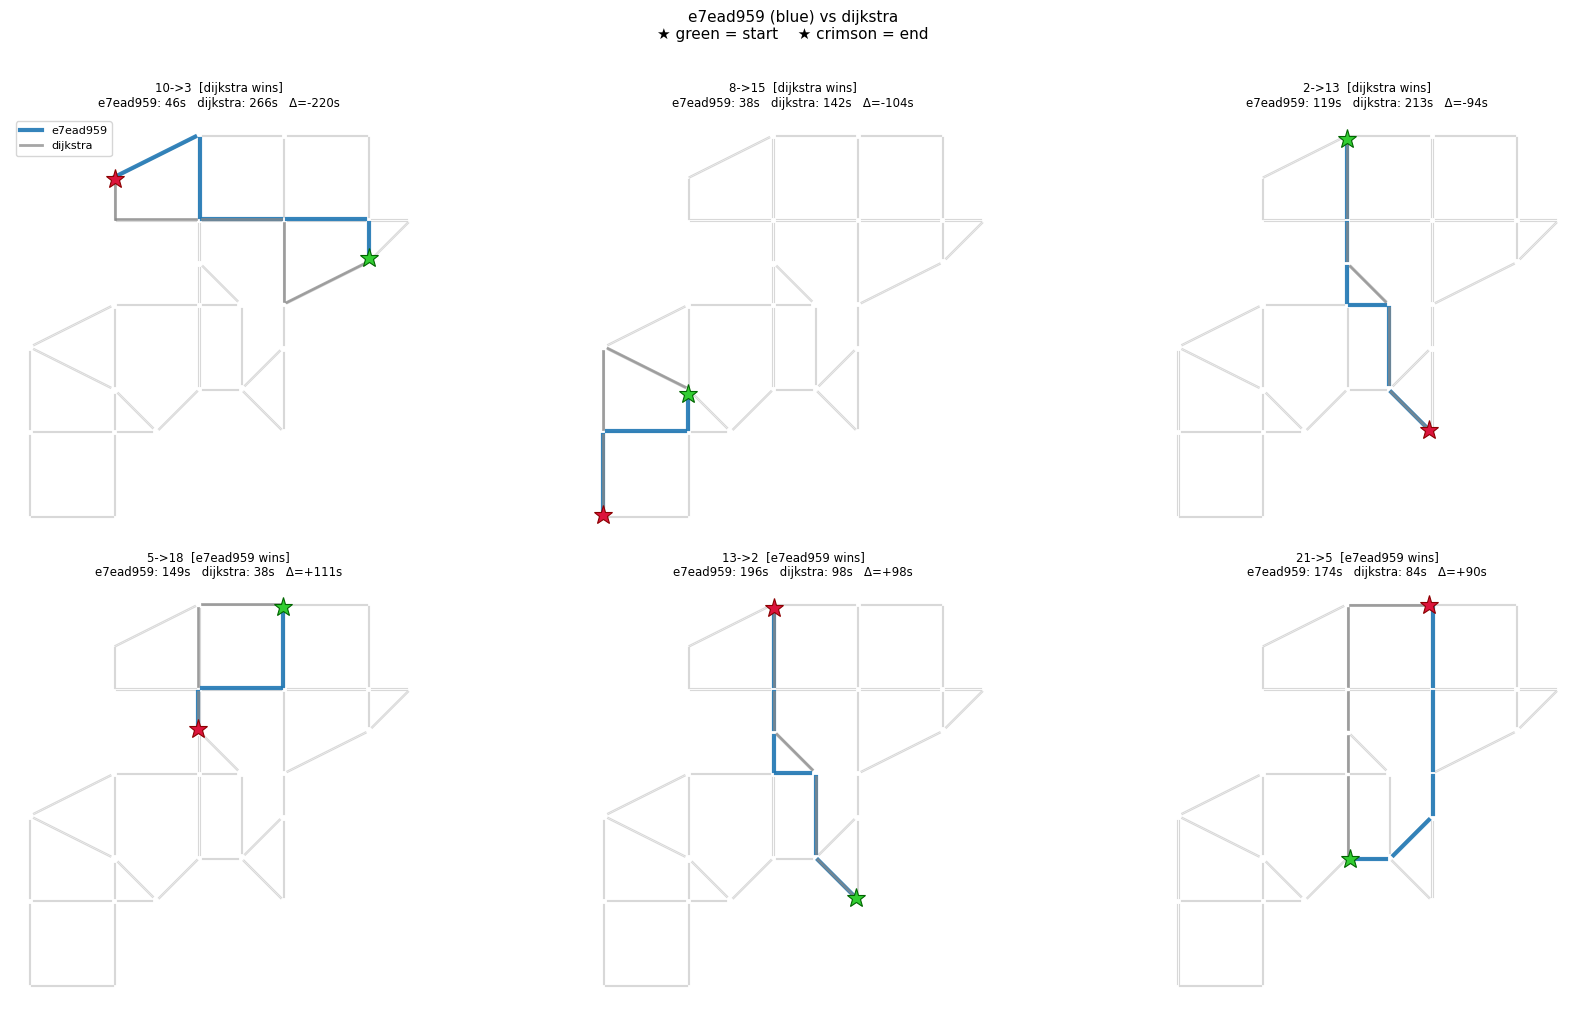

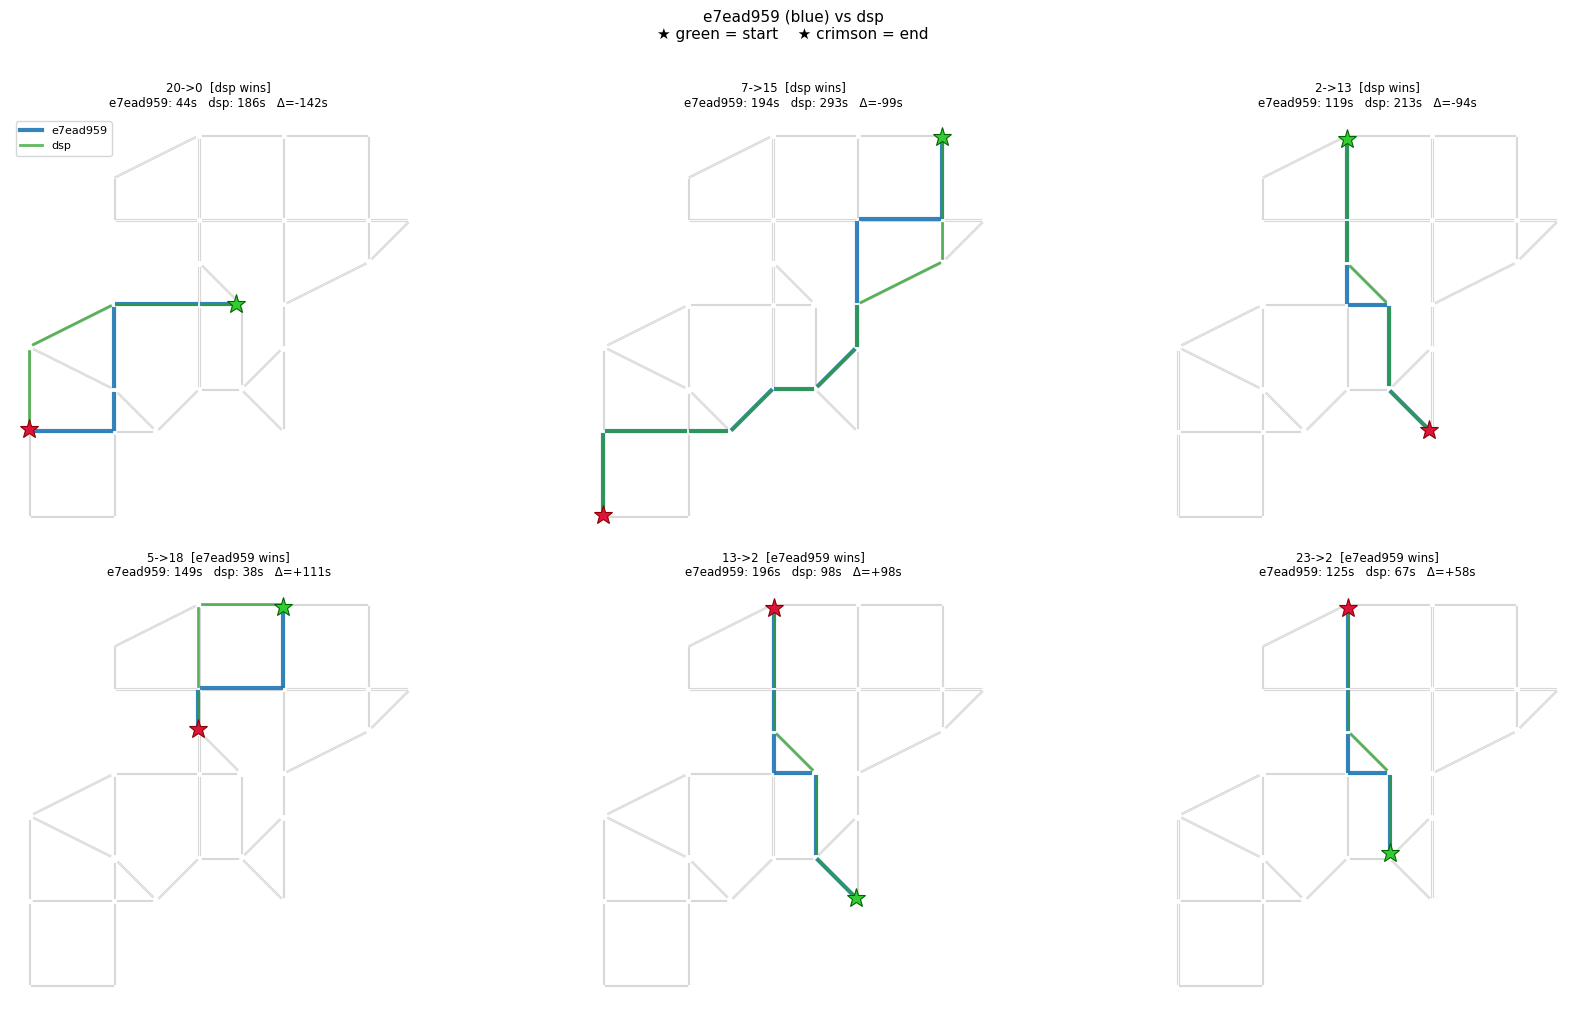

In [20]:
import sumolib
import yaml as _yaml_pe

# --- Load SUMO network for route visualization ---
_pe_cfg_path = pe_test_dir / "config.yaml"
with open(_pe_cfg_path) as _f:
    _pe_cfg = _yaml_pe.safe_load(_f)

_pe_net_xml = Path("..") / _pe_cfg["net"]["net_path"].replace(".sumocfg", ".net.xml")
_pe_net = sumolib.net.readNet(str(_pe_net_xml), withPedestrianConnections=False)

pe_edge_shape = {}
pe_node_pos   = {}
for _e in _pe_net.getEdges():
    _eid = _e.getID()
    if _eid.startswith(":"): continue
    _shp = _e.getShape()
    if _shp: pe_edge_shape[_eid] = _shp
    for _nd in (_e.getFromNode(), _e.getToNode()):
        _nid = _nd.getID()
        if _nid not in pe_node_pos:
            _s = _nd.getShape()
            if _s:
                pe_node_pos[_nid] = (sum(p[0] for p in _s) / len(_s),
                                     sum(p[1] for p in _s) / len(_s))
print(f"Network: {_pe_net_xml}  nodes={len(pe_node_pos)}  edges={len(pe_edge_shape)}")


def _pe_draw_net(ax):
    for eid, shp in pe_edge_shape.items():
        ax.plot([p[0] for p in shp], [p[1] for p in shp],
                color="#d8d8d8", lw=0.8, zorder=1)


def _pe_draw_path(ax, path_str, color, lw=2.8, alpha=0.9, zorder=4, label=None):
    edges = [e.strip() for e in str(path_str).split(";")
             if e.strip() and e.strip() in pe_edge_shape]
    for i, eid in enumerate(edges):
        shp = pe_edge_shape[eid]
        ax.plot([p[0] for p in shp], [p[1] for p in shp],
                color=color, lw=lw, alpha=alpha, zorder=zorder,
                label=label if i == 0 else None)
    return bool(edges)


def _pe_mark_ends(ax, *path_strs):
    for ps in path_strs:
        edges = [e.strip() for e in str(ps).split(";") if e.strip()]
        if edges and edges[0] in pe_edge_shape:
            s = pe_edge_shape[edges[0]][0]
            ax.plot(s[0], s[1], "*", color="limegreen", ms=14, zorder=7,
                    markeredgecolor="darkgreen", mew=0.8)
            break
    for ps in reversed(path_strs):
        edges = [e.strip() for e in str(ps).split(";") if e.strip()]
        if edges and edges[-1] in pe_edge_shape:
            e = pe_edge_shape[edges[-1]][-1]
            ax.plot(e[0], e[1], "*", color="crimson", ms=14, zorder=7,
                    markeredgecolor="darkred", mew=0.8)
            break


# --- Best / worst routes: policy vs dijkstra, then policy vs dsp ---
N_HIGHLIGHT = 3
t_pol, t_dij, t_dsp = pe_times
lbl_a = pe_labels[0]
col_a = _PE_COLORS[lbl_a]

for lbl_b, t_b in [("dijkstra", t_dij), ("dsp", t_dsp)]:
    col_b = _PE_COLORS[lbl_b]
    diff  = t_pol - t_b  # negative → b wins, positive → a wins

    worst_for_a = list(np.argsort(diff)[:N_HIGHLIGHT])     # b wins most
    best_for_a  = list(np.argsort(diff)[-N_HIGHLIGHT:][::-1])  # a wins most

    highlight_idxs = worst_for_a + best_for_a
    row_titles     = [f"{lbl_b} wins"] * N_HIGHLIGHT + [f"{lbl_a} wins"] * N_HIGHLIGHT

    fig, axes = plt.subplots(2, N_HIGHLIGHT, figsize=(6 * N_HIGHLIGHT, 10))
    fig.suptitle(
        f"{lbl_a} (blue) vs {lbl_b}\n★ green = start    ★ crimson = end",
        fontsize=11, y=1.01,
    )
    df_b = pe_dfs[pe_labels.index(lbl_b)]

    for i, (ri, title) in enumerate(zip(highlight_idxs, row_titles)):
        r, c = divmod(i, N_HIGHLIGHT)
        ax = axes[r][c]
        row_a = pe_dfs[0].iloc[ri]
        row_b = df_b.iloc[ri]

        _pe_draw_net(ax)
        _pe_draw_path(ax, row_a[_PE_PATH_COL], col_a, lw=3.0, zorder=4, label=lbl_a)
        _pe_draw_path(ax, row_b[_PE_PATH_COL], col_b, lw=2.0, alpha=0.75, zorder=5, label=lbl_b)
        _pe_mark_ends(ax, str(row_a[_PE_PATH_COL]), str(row_b[_PE_PATH_COL]))

        ta, tb = row_a[_PE_TIME_COL], row_b[_PE_TIME_COL]
        ax.set_title(
            f"{row_a['route_key']}  [{title}]\n"
            f"{lbl_a}: {ta:.0f}s   {lbl_b}: {tb:.0f}s   Δ={ta - tb:+.0f}s",
            fontsize=8.5,
        )
        ax.set_aspect("equal"); ax.axis("off")
        if i == 0:
            ax.legend(fontsize=8, loc="upper left", framealpha=0.8)

    plt.tight_layout()
    plt.show()

# Policy vs Policy (Common Routes Only)

This section compares two policies only on `(start_idx, target_idx)` pairs that both completed successfully.

- `algo1` and `algo2` can be any policy ID, or `"dij"` to resolve the Dijkstra baseline folder.
- Success/completion is defined from `failed_error`.
- Duplicate OD pairs (if any) are collapsed to the fastest successful row per pair before comparison.
- Completion-time comparisons include box plot, mean bar chart, and histogram.
- Route-level plots use a consistent `route_index` after sorting by `(start_idx, target_idx)`.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# --- User-editable algorithm selectors ---
# Set to any policy ID (e.g. "b3ef6da6") or "dij" for the Dijkstra baseline folder
algo1 = "dsp"
algo2 = "2553013e"

# --- Helpers ---
def resolve_algo_dir(runs_root: Path, algo_hint: str) -> Path:
    algo_hint = algo_hint.strip().lower()
    candidates = [p for p in runs_root.iterdir() if p.is_dir()]

    exact = [p for p in candidates if p.name.lower() == algo_hint]
    if exact:
        return exact[0]

    fuzzy = [
        p for p in candidates
        if p.name.lower().startswith(algo_hint) or algo_hint in p.name.lower()
    ]
    if len(fuzzy) == 1:
        return fuzzy[0]
    if len(fuzzy) > 1:
        return sorted(fuzzy, key=lambda p: (len(p.name), p.name))[0]

    raise ValueError(f"No algorithm directory found under {runs_root} for hint: {algo_hint!r}")


def latest_test_csv(algo_dir: Path) -> Path:
    tests = [p for p in algo_dir.glob("test_*") if p.is_dir()]
    if not tests:
        raise ValueError(f"No test_* directories found in {algo_dir}")

    def test_index(path: Path):
        m = re.match(r"test_(\d+)$", path.name)
        return int(m.group(1)) if m else -1

    selected = sorted(tests, key=lambda p: (test_index(p), p.stat().st_mtime))[-1]
    csv_path = selected / "simulation_results.csv"
    if not csv_path.exists():
        raise ValueError(f"Missing simulation_results.csv in {selected}")
    return csv_path


def is_completed_from_failed_error(series: pd.Series) -> pd.Series:
    as_str = series.astype("string").str.strip().str.lower()
    return series.isna() | as_str.isin(["", "na", "nan", "none"])


# --- Inputs ---
runs_root = Path("../runs/trsp")
algo1_dir = resolve_algo_dir(runs_root, algo1)
algo2_dir = resolve_algo_dir(runs_root, algo2)

algo1_csv = latest_test_csv(algo1_dir)
algo2_csv = latest_test_csv(algo2_dir)

algo1_label = algo1_dir.name
algo2_label = algo2_dir.name

key_cols = ["start_idx", "target_idx"]
time_col = "total_time_taken"
path_col = "path_edges"
success_col = "failed_error"
required_cols = key_cols + [time_col, path_col, success_col]

# --- Load ---
df_algo1 = pd.read_csv(algo1_csv)
df_algo2 = pd.read_csv(algo2_csv)

for name, df in [(algo1_label, df_algo1), (algo2_label, df_algo2)]:
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing required columns: {missing}")

for df in [df_algo1, df_algo2]:
    df["start_idx"] = pd.to_numeric(df["start_idx"], errors="coerce").astype("Int64")
    df["target_idx"] = pd.to_numeric(df["target_idx"], errors="coerce").astype("Int64")
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

print(f"Using files -> {algo1_label}: {algo1_csv}")
print(f"Using files -> {algo2_label}: {algo2_csv}")

# --- SUCCESS filtering ---
success_algo1_full = is_completed_from_failed_error(df_algo1[success_col]) & (df_algo1[time_col] > 0)
success_algo2_full = is_completed_from_failed_error(df_algo2[success_col]) & (df_algo2[time_col] > 0)

df_algo1_success = df_algo1.loc[success_algo1_full].copy()
df_algo2_success = df_algo2.loc[success_algo2_full].copy()

print(f"Successful rows -> {algo1_label}: {len(df_algo1_success)}/{len(df_algo1)}, "
      f"{algo2_label}: {len(df_algo2_success)}/{len(df_algo2)}")

# --- Deduplicate: keep the fastest row per (start_idx, target_idx) ---
# Duplicate OD pairs arise from eval restarts; keeping min-time is most conservative.
df_algo1_success = (df_algo1_success
                    .sort_values(time_col)
                    .drop_duplicates(subset=key_cols, keep="first")
                    .reset_index(drop=True))
df_algo2_success = (df_algo2_success
                    .sort_values(time_col)
                    .drop_duplicates(subset=key_cols, keep="first")
                    .reset_index(drop=True))

print(f"After dedup -> {algo1_label}: {len(df_algo1_success)}, {algo2_label}: {len(df_algo2_success)}")

# --- Intersect: keep only OD pairs both algorithms completed ---
pairs_algo1 = set(zip(df_algo1_success["start_idx"], df_algo1_success["target_idx"]))
pairs_algo2 = set(zip(df_algo2_success["start_idx"], df_algo2_success["target_idx"]))
common_pairs = pairs_algo1 & pairs_algo2

mask_algo1 = df_algo1_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)
mask_algo2 = df_algo2_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)

df_algo1_common = df_algo1_success.loc[mask_algo1].sort_values(key_cols).reset_index(drop=True)
df_algo2_common = df_algo2_success.loc[mask_algo2].sort_values(key_cols).reset_index(drop=True)

assert len(df_algo1_common) == len(df_algo2_common), \
    f"Row mismatch after dedup+intersect: {algo1_label}={len(df_algo1_common)} vs {algo2_label}={len(df_algo2_common)}"

same_keys = (df_algo1_common[key_cols].values == df_algo2_common[key_cols].values).all()
assert same_keys, "Route ordering mismatch after sorting common pairs."

# --- Same-path adjustment: if both took identical edges, credit both with min time ---
path1 = df_algo1_common[path_col].astype("string").fillna("").str.strip()
path2 = df_algo2_common[path_col].astype("string").fillna("").str.strip()
same_path_mask = path1 == path2

min_shared_time = np.minimum(df_algo1_common[time_col].values, df_algo2_common[time_col].values)
df_algo1_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]
df_algo2_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]

print(f"Same-path rows adjusted to shared min time: {int(same_path_mask.sum())}")

df_algo1_common["route_index"] = np.arange(len(df_algo1_common))
df_algo2_common["route_index"] = np.arange(len(df_algo2_common))

route_key = (df_algo1_common["start_idx"].astype(str) + "->" + df_algo1_common["target_idx"].astype(str))
df_algo1_common["route_key"] = route_key
df_algo2_common["route_key"] = route_key

# --- Summary ---
summary = pd.DataFrame({
    "algorithm": [algo1_label, algo2_label],
    "completed_routes_in_full_df": [int(success_algo1_full.sum()), int(success_algo2_full.sum())],
    "total_routes_in_full_df": [len(df_algo1), len(df_algo2)],
    "routes_used_for_comparison": [len(df_algo1_common), len(df_algo2_common)],
})
summary["success_rate_pct_full_df"] = (
    100 * summary["completed_routes_in_full_df"] / summary["total_routes_in_full_df"]
)

print(f"Common successful OD pairs: {len(common_pairs)}")
print("\nSuccess summary:")
display(summary)

aligned = pd.DataFrame({
    "route_index": df_algo1_common["route_index"],
    "start_idx":   df_algo1_common["start_idx"],
    "target_idx":  df_algo1_common["target_idx"],
    "route_key":   df_algo1_common["route_key"],
    f"{algo1_label}_time":  df_algo1_common[time_col],
    f"{algo2_label}_time":  df_algo2_common[time_col],
    f"{algo1_label}_edges": df_algo1_common[path_col],
    f"{algo2_label}_edges": df_algo2_common[path_col],
})
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"
aligned[diff_col] = aligned[f"{algo2_label}_time"] - aligned[f"{algo1_label}_time"]

time_summary = pd.DataFrame({
    "algorithm":   [algo1_label, algo2_label],
    "mean_time":   [df_algo1_common[time_col].mean(),   df_algo2_common[time_col].mean()],
    "median_time": [df_algo1_common[time_col].median(), df_algo2_common[time_col].median()],
    "min_time":    [df_algo1_common[time_col].min(),    df_algo2_common[time_col].min()],
    "max_time":    [df_algo1_common[time_col].max(),    df_algo2_common[time_col].max()],
})

print("\nTime summary (successful common OD routes, same-path adjusted):")
display(time_summary)
display(aligned.head(10))

Using files -> dsp: ../runs/trsp/dsp/test_3/simulation_results.csv
Using files -> 2553013e: ../runs/trsp/2553013e/test_0/simulation_results.csv
Successful rows -> dsp: 100/100, 2553013e: 75/100
After dedup -> dsp: 94, 2553013e: 70
Same-path rows adjusted to shared min time: 37
Common successful OD pairs: 70

Success summary:


,algorithm,completed_routes_in_full_df,total_routes_in_full_df,routes_used_for_comparison,success_rate_pct_full_df
0,dsp,100,100,70,100.0
1,2553013e,75,100,70,75.0



Time summary (successful common OD routes, same-path adjusted):


,algorithm,mean_time,median_time,min_time,max_time
0,dsp,46.914286,35.5,1.0,208.0
1,2553013e,52.871429,37.0,1.0,366.0


,route_index,start_idx,target_idx,route_key,dsp_time,2553013e_time,dsp_edges,2553013e_edges,time_diff_2553013e_minus_dsp
0,0,0,3,0->3,100.0,226.0,11;-49;53;59;71;95;112,11;-39;38;65;78;-396;-284;-260;256;-147;137;-1...,126.0
1,1,0,18,0->18,1.0,1.0,7;33;65;-63;59,7;33;65;-63;59,0.0
2,2,0,24,0->24,1.0,120.0,7;33;65;-63;59;71;95,11;-39;-15;33;65;-63;59;71;95,119.0
3,3,0,25,0->25,111.0,1.0,7;33;65;-63;59;71;99,7;33;65;-63;61;-69;71;101;126;-120,-110.0
4,4,1,0,1->0,1.0,1.0,-11,-11,0.0
5,5,1,24,1->24,102.0,91.0,-39;38;65;-63;59;71;95,-39;-15;33;65;-63;59;71;95,-11.0
6,6,2,1,2->1,64.0,64.0,-101;-71;-59;-53;49,-101;-71;-59;-53;49,0.0
7,7,2,8,2->8,1.0,1.0,-101;-71;-59;-53;-43,-101;-71;-59;-53;-43,0.0
8,8,2,13,2->13,1.0,1.0,-101;-71;69;84;-396,-101;-71;69;84;-396,0.0
9,9,2,19,2->19,1.0,1.0,-101;-71;-59;63;-65;-33,-101;-71;-59;-53;-43;-15,0.0


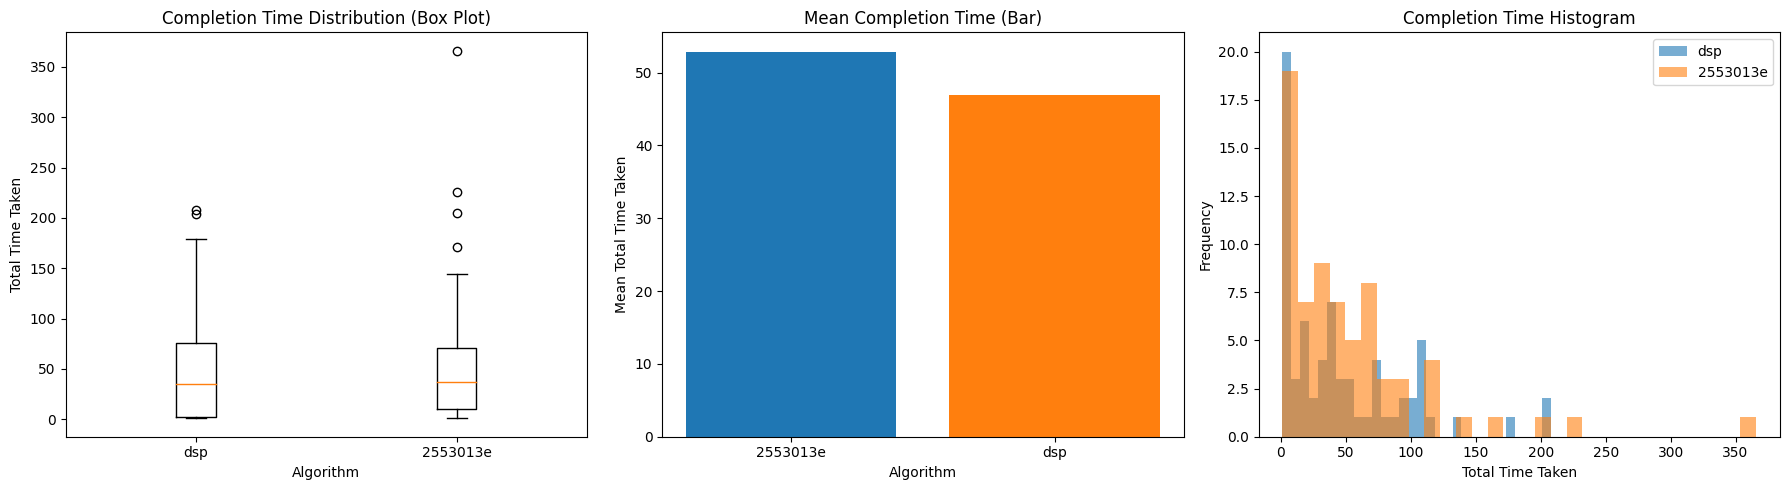

In [17]:
# --- Time comparison plots: box, mean bar, histogram ---
plot_df = pd.concat(
    [
        pd.DataFrame({"algorithm": algo1_label, "total_time_taken": df_algo1_common["total_time_taken"]}),
        pd.DataFrame({"algorithm": algo2_label, "total_time_taken": df_algo2_common["total_time_taken"]}),
    ],
    ignore_index=True,
)

means = (
    plot_df.groupby("algorithm", as_index=False)["total_time_taken"]
    .mean()
    .rename(columns={"total_time_taken": "mean_total_time_taken"})
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
algorithms = [algo1_label, algo2_label]
box_data = [
    plot_df.loc[plot_df["algorithm"] == algo, "total_time_taken"].dropna().values
    for algo in algorithms
]
axes[0].boxplot(box_data, labels=algorithms)
axes[0].set_title("Completion Time Distribution (Box Plot)")
axes[0].set_xlabel("Algorithm")
axes[0].set_ylabel("Total Time Taken")

# Mean bar chart
axes[1].bar(means["algorithm"], means["mean_total_time_taken"], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Mean Completion Time (Bar)")
axes[1].set_xlabel("Algorithm")
axes[1].set_ylabel("Mean Total Time Taken")

# Histogram overlay
bins = 30
axes[2].hist(df_algo1_common["total_time_taken"], bins=bins, alpha=0.6, label=algo1_label)
axes[2].hist(df_algo2_common["total_time_taken"], bins=bins, alpha=0.6, label=algo2_label)
axes[2].set_title("Completion Time Histogram")
axes[2].set_xlabel("Total Time Taken")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

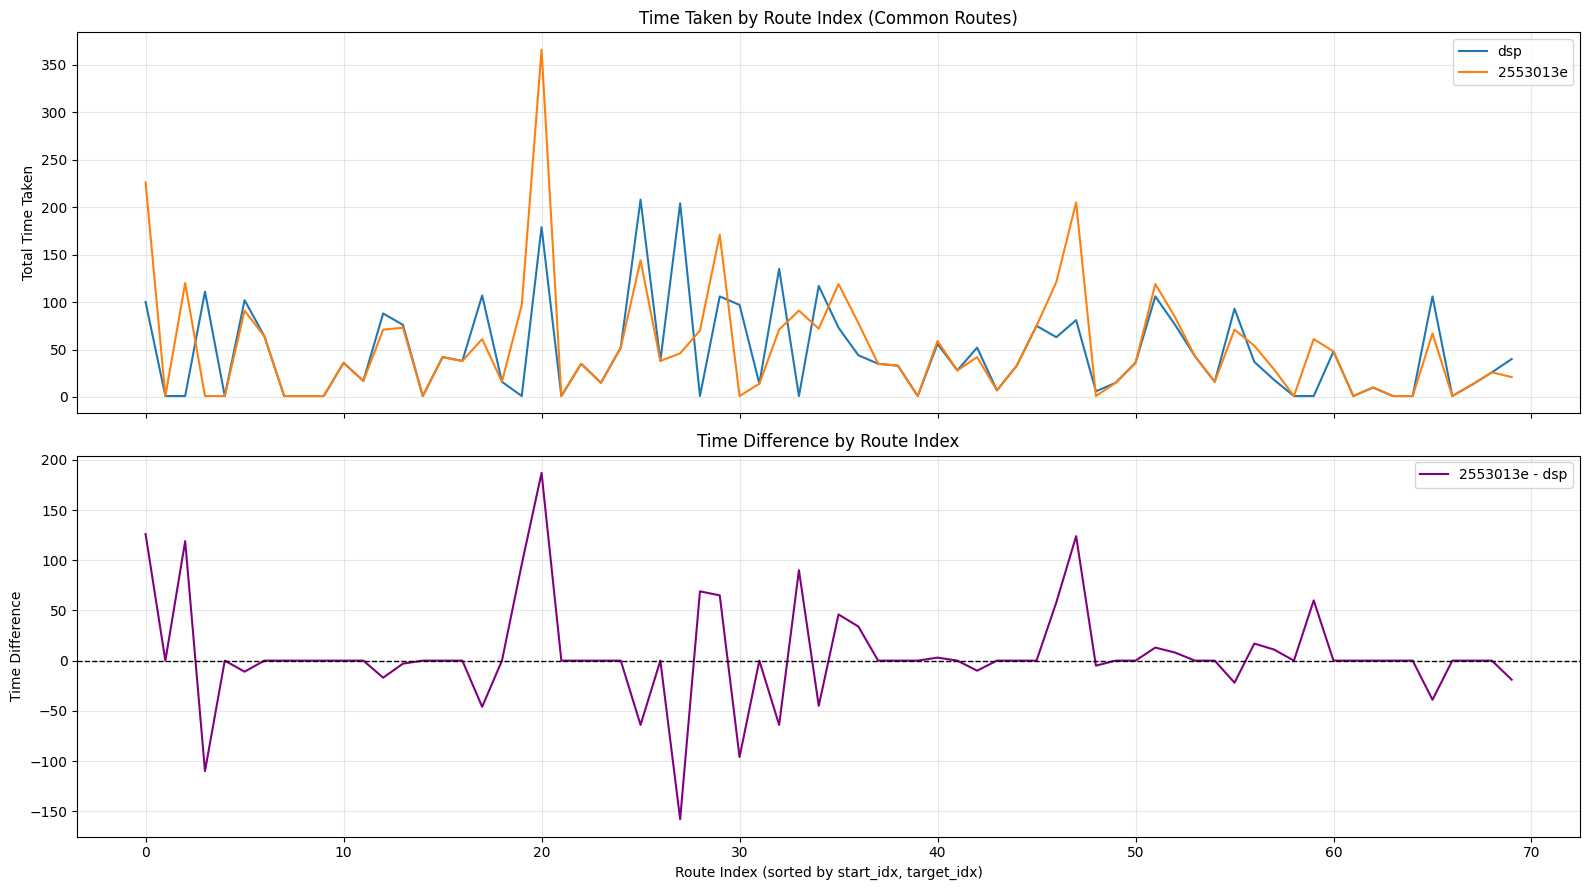

Mean time difference (2553013e - dsp): 5.957142857142857
Routes where 2553013e is faster (diff < 0): 15
Routes where dsp is faster (diff > 0): 17
Routes with equal time: 38


In [18]:
# --- Route index plots: raw times and time difference ---
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

axes[0].plot(aligned["route_index"], aligned[time_col_algo1], label=algo1_label, linewidth=1.5)
axes[0].plot(aligned["route_index"], aligned[time_col_algo2], label=algo2_label, linewidth=1.5)
axes[0].set_title("Time Taken by Route Index (Common Routes)")
axes[0].set_ylabel("Total Time Taken")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    aligned["route_index"],
    aligned[diff_col],
    color="purple",
    linewidth=1.5,
    label=f"{algo2_label} - {algo1_label}",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Difference by Route Index")
axes[1].set_xlabel("Route Index (sorted by start_idx, target_idx)")
axes[1].set_ylabel("Time Difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean time difference ({algo2_label} - {algo1_label}):", aligned[diff_col].mean())
print(f"Routes where {algo2_label} is faster (diff < 0):", (aligned[diff_col] < 0).sum())
print(f"Routes where {algo1_label} is faster (diff > 0):", (aligned[diff_col] > 0).sum())
print("Routes with equal time:", (aligned[diff_col] == 0).sum())

Top 10 BEST routes for 2553013e vs dsp (most negative diff):


,route_index,route_key,dsp_time,2553013e_time,time_diff_2553013e_minus_dsp
27,27,8->17,204.0,46.0,-158.0
3,3,0->25,111.0,1.0,-110.0
30,30,11->5,97.0,1.0,-96.0
25,25,8->7,208.0,144.0,-64.0
32,32,11->20,135.0,71.0,-64.0
17,17,5->23,107.0,61.0,-46.0
34,34,13->1,117.0,72.0,-45.0
65,65,24->8,106.0,67.0,-39.0
55,55,21->5,93.0,71.0,-22.0
69,69,25->10,40.0,21.0,-19.0


Top 10 WORST routes for 2553013e vs dsp (most positive diff):


,route_index,route_key,dsp_time,2553013e_time,time_diff_2553013e_minus_dsp
20,20,7->15,179.0,366.0,187.0
0,0,0->3,100.0,226.0,126.0
47,47,19->6,81.0,205.0,124.0
2,2,0->24,1.0,120.0,119.0
19,19,7->8,1.0,97.0,96.0
33,33,12->11,1.0,91.0,90.0
28,28,9->2,1.0,70.0,69.0
29,29,10->8,106.0,171.0,65.0
59,59,22->7,1.0,61.0,60.0
46,46,18->9,63.0,121.0,58.0


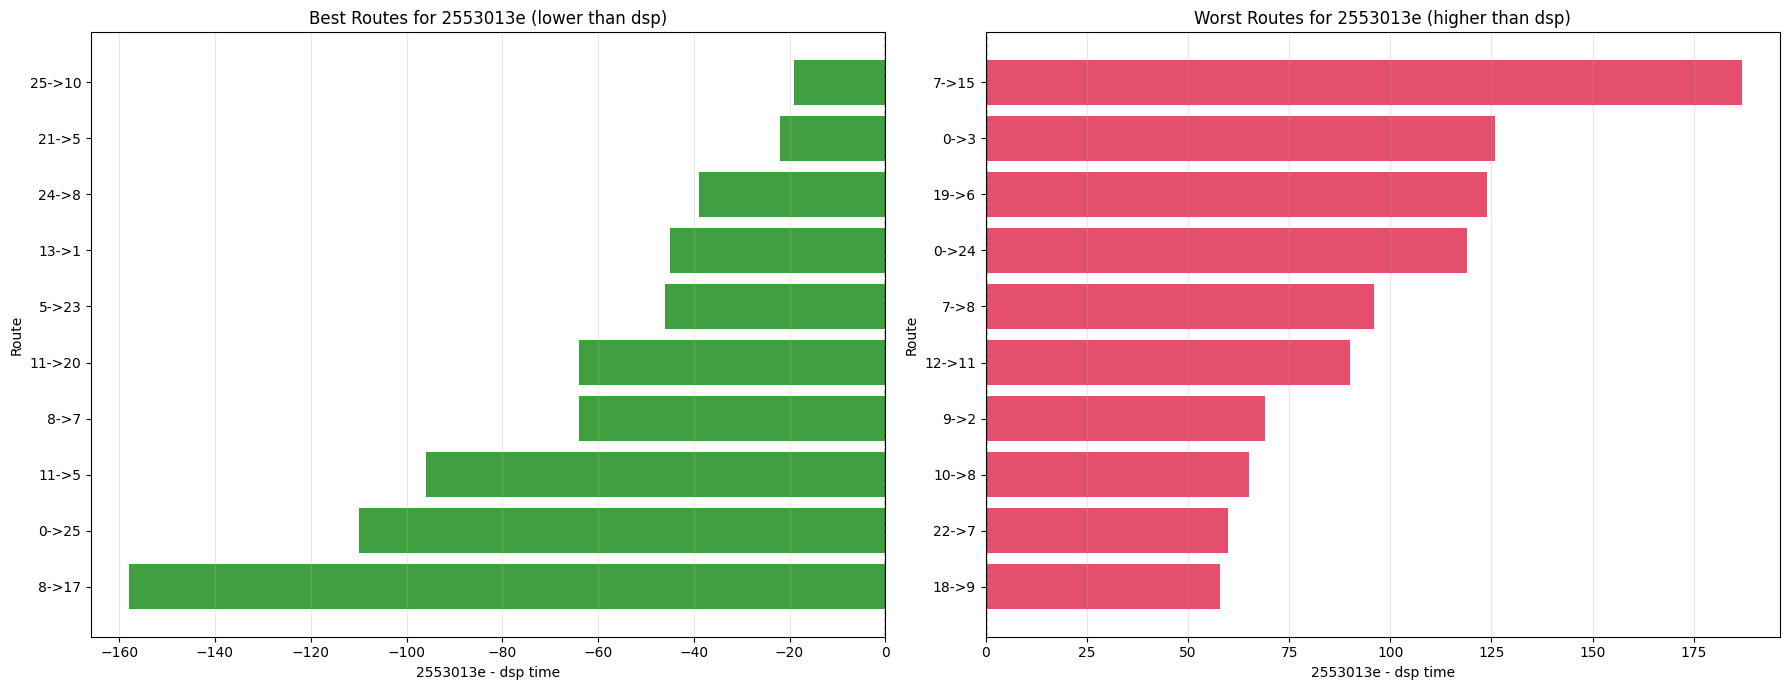

In [19]:
# --- Best and worst routes between the two algorithms ---
# diff_col is defined as: algo2_time - algo1_time
#   negative -> algo2 faster, positive -> algo1 faster

top_k = 10

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

best_for_algo2 = aligned.nsmallest(top_k, diff_col).copy()
worst_for_algo2 = aligned.nlargest(top_k, diff_col).copy()

show_cols = ["route_index", "route_key", time_col_algo1, time_col_algo2, diff_col]

print(f"Top {top_k} BEST routes for {algo2_label} vs {algo1_label} (most negative diff):")
display(best_for_algo2[show_cols])

print(f"Top {top_k} WORST routes for {algo2_label} vs {algo1_label} (most positive diff):")
display(worst_for_algo2[show_cols])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=False)

left_df = best_for_algo2.sort_values(diff_col, ascending=True)
right_df = worst_for_algo2.sort_values(diff_col, ascending=True)

axes[0].barh(left_df["route_key"], left_df[diff_col], color="green", alpha=0.75)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"Best Routes for {algo2_label} (lower than {algo1_label})")
axes[0].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[0].set_ylabel("Route")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(right_df["route_key"], right_df[diff_col], color="crimson", alpha=0.75)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(f"Worst Routes for {algo2_label} (higher than {algo1_label})")
axes[1].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[1].set_ylabel("Route")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

---
## Highlight Routes — Where Each Policy Shines

For the top-N routes where `algo2` wins by the largest margin and where `algo1` wins by the largest margin, draw both paths on the road network. Solid lines are the actual edge sequences from `path_edges`. Routes that differ visually reveal the detour strategies learned by the RL policy.

Network: ../data/rand_grid_road/rand_grid_road_final.net.xml
Nodes: 26   Edges: 78
  dsp_edges: sample=['7', '33', '65', '-63']  matched=['7', '33', '65', '-63']
  2553013e_edges: sample=['7', '33', '65', '-63']  matched=['7', '33', '65', '-63']


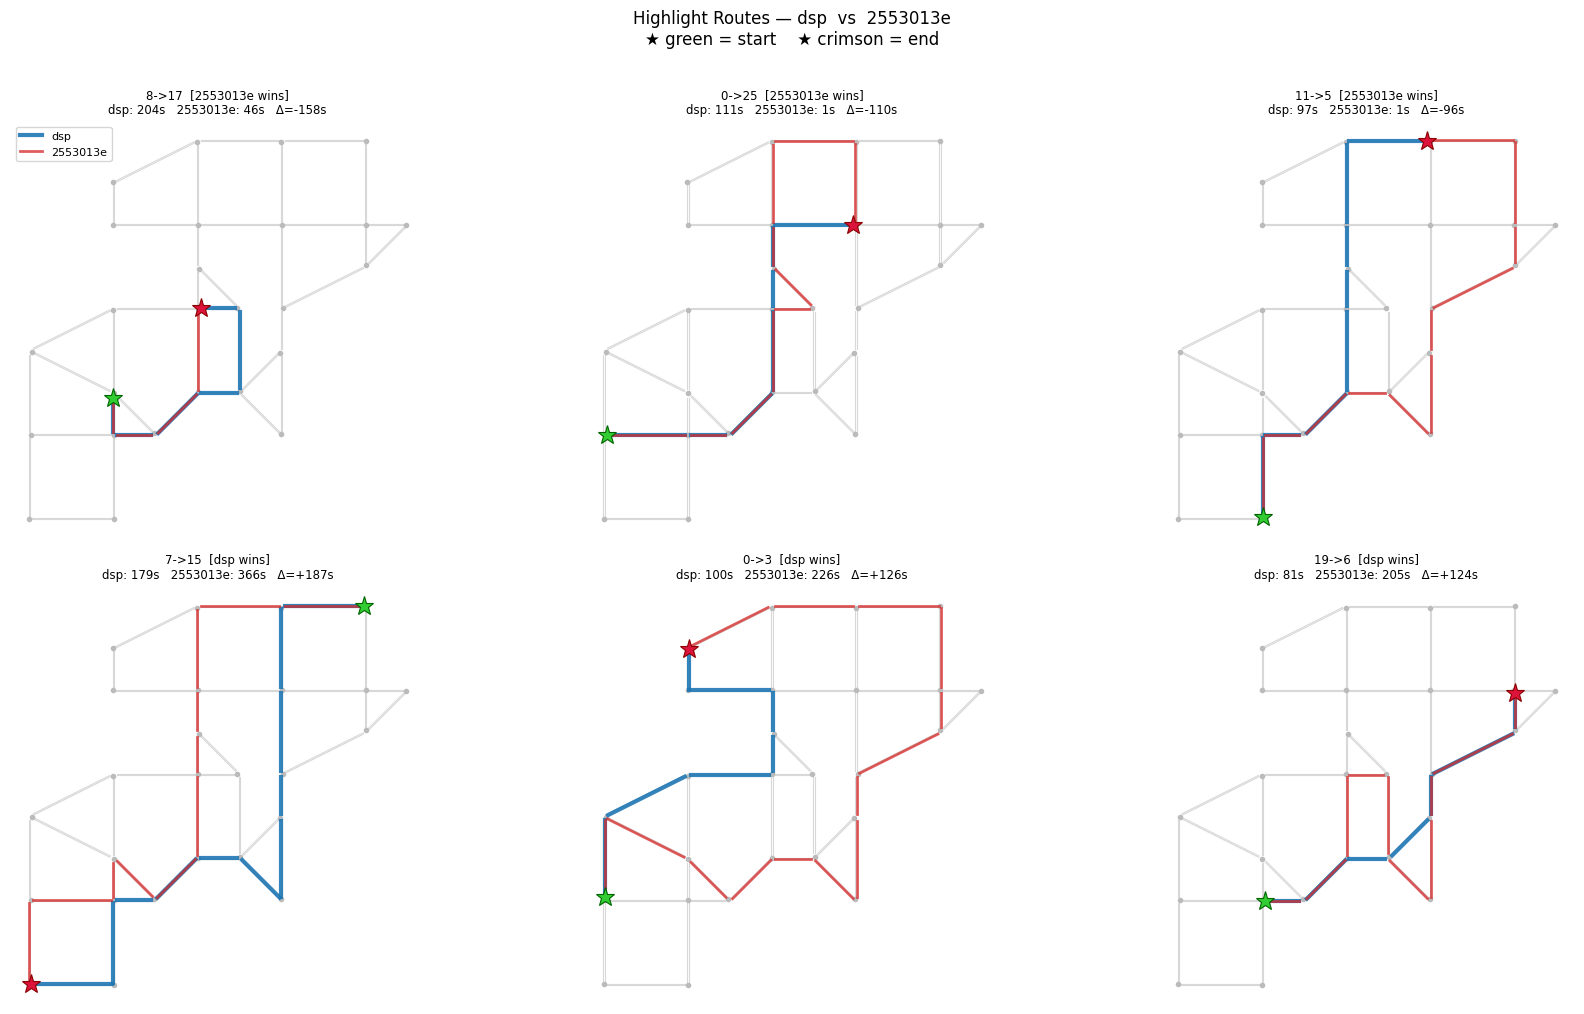

In [20]:
import sumolib
import yaml as _yaml

# --- Load network: prefer the test-level config (always exists) over the root config ---
# algo1_dir/config.yaml may not exist (e.g. dijkstra dir has no root-level config.yaml)
_cfg_candidates = [
    algo1_csv.parent / "config.yaml",   # test_N/config.yaml for algo1  ← most reliable
    algo2_csv.parent / "config.yaml",   # test_N/config.yaml for algo2
    algo1_dir / "config.yaml",          # root config (exists for trained-policy dirs)
    algo2_dir / "config.yaml",
]
_test_cfg = next((p for p in _cfg_candidates if p.exists()), None)
if _test_cfg is None:
    raise FileNotFoundError("Cannot find a config.yaml to determine net_path")

with open(_test_cfg) as _f:
    _cfg = _yaml.safe_load(_f)

_net_xml = Path("..") / _cfg["net"]["net_path"].replace(".sumocfg", ".net.xml")
print(f"Network: {_net_xml}")

_net = sumolib.net.readNet(str(_net_xml), withPedestrianConnections=False)

# --- Build maps ---
# edge_shape[eid]   → list of (x, y) shape points  (used for route drawing)
# node_pos[node_id] → (x, y) centroid
# sorted_node_ids   → same sorted order as the TRSP env's node2idx
edge_shape = {}
node_pos   = {}

for _edge in _net.getEdges():
    _eid = _edge.getID()
    if _eid.startswith(":"):
        continue
    _shape = _edge.getShape()
    if _shape:
        edge_shape[_eid] = _shape
    for _nd in (_edge.getFromNode(), _edge.getToNode()):
        _nid = _nd.getID()
        if _nid not in node_pos:
            _s = _nd.getShape()
            if _s:
                node_pos[_nid] = (
                    sum(p[0] for p in _s) / len(_s),
                    sum(p[1] for p in _s) / len(_s),
                )

# node index → (x, y), matching the env's sorted-node ordering
sorted_node_ids  = sorted(node_pos.keys())
node_idx_to_pos  = {i: node_pos[nid] for i, nid in enumerate(sorted_node_ids)}

print(f"Nodes: {len(node_pos)}   Edges: {len(edge_shape)}")

# --- Debug: verify that edge IDs in the eval CSVs match sumolib ---
for _col in (f"{algo1_label}_edges", f"{algo2_label}_edges"):
    if _col in aligned.columns:
        _notnull = aligned[_col].dropna()
        _sample_str = str(_notnull.iloc[1]) if len(_notnull) > 1 else ""
        _sample_ids = [e.strip() for e in _sample_str.split(";") if e.strip()][:4]
        _hits = [e for e in _sample_ids if e in edge_shape]
        print(f"  {_col}: sample={_sample_ids}  matched={_hits}")

# ------------------------------------------------------------------ helpers

def _parse_edges(edge_str):
    s = str(edge_str).strip().lower()
    if not s or s in ("nan", "-1", ""):
        return []
    return [e.strip() for e in str(edge_str).split(";") if e.strip()]

def _draw_network_bg(ax):
    for _eid, _shp in edge_shape.items():
        ax.plot([p[0] for p in _shp], [p[1] for p in _shp],
                color="#d8d8d8", lw=0.8, zorder=1)
    for _nid, (_x, _y) in node_pos.items():
        ax.plot(_x, _y, "o", color="#bbbbbb", ms=3, zorder=2)

def _draw_route_edges(ax, edge_list, color, lw=2.8, alpha=0.9, zorder=4, label=None):
    """Draw each edge in edge_list using its sumolib shape. Returns True if anything was drawn."""
    first = True
    for eid in edge_list:
        if eid in edge_shape:
            shp = edge_shape[eid]
            ax.plot([p[0] for p in shp], [p[1] for p in shp],
                    color=color, lw=lw, alpha=alpha, zorder=zorder,
                    label=label if first else None)
            first = False
    return not first   # True iff at least one edge was drawn

def _mark_endpoints(ax, edge_list, start_idx, end_idx):
    """Mark start ★ (green) and end ★ (crimson); fall back to node-index position."""
    # Start
    if edge_list and edge_list[0] in edge_shape:
        s = edge_shape[edge_list[0]][0]
    elif start_idx in node_idx_to_pos:
        s = node_idx_to_pos[start_idx]
    else:
        s = None
    if s:
        ax.plot(s[0], s[1], "*", color="limegreen", ms=14, zorder=7,
                markeredgecolor="darkgreen", mew=0.8)

    # End
    if edge_list and edge_list[-1] in edge_shape:
        e = edge_shape[edge_list[-1]][-1]
    elif end_idx in node_idx_to_pos:
        e = node_idx_to_pos[end_idx]
    else:
        e = None
    if e:
        ax.plot(e[0], e[1], "*", color="crimson", ms=14, zorder=7,
                markeredgecolor="darkred", mew=0.8)

# ------------------------------------------------------------------ select highlight rows

N = 3
highlight_rows = pd.concat([
    aligned.nsmallest(N, diff_col),   # algo2 wins by most
    aligned.nlargest(N, diff_col),    # algo1 wins by most
], ignore_index=True)

row_labels = [f"{algo2_label} wins"] * N + [f"{algo1_label} wins"] * N
COLORS     = {algo1_label: "#1f77b4", algo2_label: "#d62728"}

# ------------------------------------------------------------------ plot

fig, axes = plt.subplots(2, N, figsize=(6 * N, 10))
fig.suptitle(
    f"Highlight Routes — {algo1_label}  vs  {algo2_label}\n"
    "★ green = start    ★ crimson = end",
    fontsize=12, y=1.01,
)

for i, (_, row) in enumerate(highlight_rows.iterrows()):
    r, c = divmod(i, N)
    ax   = axes[r][c]

    edges1 = _parse_edges(row.get(f"{algo1_label}_edges", ""))
    edges2 = _parse_edges(row.get(f"{algo2_label}_edges", ""))
    s_idx  = int(row["start_idx"])
    t_idx  = int(row["target_idx"])

    _draw_network_bg(ax)
    drawn1 = _draw_route_edges(ax, edges1, COLORS[algo1_label], lw=3.0, zorder=4, label=algo1_label)
    drawn2 = _draw_route_edges(ax, edges2, COLORS[algo2_label], lw=2.0, alpha=0.75, zorder=5, label=algo2_label)

    _mark_endpoints(ax, edges1 if drawn1 else edges2, s_idx, t_idx)

    t1   = row[f"{algo1_label}_time"]
    t2   = row[f"{algo2_label}_time"]
    diff = row[diff_col]
    ax.set_title(
        f"{row['route_key']}  [{row_labels[i]}]\n"
        f"{algo1_label}: {t1:.0f}s   {algo2_label}: {t2:.0f}s   Δ={diff:+.0f}s",
        fontsize=8.5,
    )
    ax.set_aspect("equal")
    ax.axis("off")
    if i == 0:
        ax.legend(fontsize=8, loc="upper left", framealpha=0.8)

plt.tight_layout()
plt.show()

---
# Aggregated Results — All Policies

Scans every `runs/trsp/*/test_N/` folder, infers `(network, traffic)` from the test config, and writes one row per `(network, traffic, model)` combination to `results/trsp_results.csv`.

Traffic conditions covered:
- **PSL (K=1–4)** — pre-loaded from `results/trsp_results_psl.csv`
- **SVC** — stochastic vehicular congestion; scanned from `runs/trsp/`
- **TD** — 3-period time-of-day congestion (Lu et al. 2020); scanned from `runs/trsp/`

For SVC/TD, each model's own row uses its own highest-numbered `test_N/`. The **Dijkstra/DSP baseline rows are the exception**: they always come from SARSA's latest `test_N/` for that `(network, traffic)`, not from whichever policy happens to have the highest test number — different agents' eval runs can use different `sumo.traffic_scale` settings, so picking an arbitrary policy's co-located baseline mixed incompatible traffic intensities into the same bar.

In [2]:
import os
import yaml
import pandas as pd
import numpy as np

TRSP_DIR     = '../runs/trsp'
PSL_CSV      = '../results/trsp_results_psl.csv'
# Skip pure-baseline directories (dijkstra, dsp, dsp_svc_rand_grid, …)
SKIP_PREFIXES = ('dijkstra', 'dsp')


def infer_network_id(net_path):
    if 'rand_grid_road' in net_path: return 'N2'
    if 'grid_road'      in net_path: return 'N1'
    if 'ames'           in net_path: return 'N3'
    return 'UNKNOWN'


def infer_traffic_id(traffic_cfg):
    if traffic_cfg is None:
        return 'T0'
    model = traffic_cfg.get('model', 'psl')
    if model == 'svc':
        route_file = traffic_cfg.get('route_file', '')
        tag = os.path.basename(os.path.dirname(route_file)) or 'svc'
        return f'SVC-{tag}'
    if model == 'td':
        return 'TD'
    K = traffic_cfg.get('K', 1)
    return {1: 'T1', 2: 'T2', 3: 'T3', 4: 'T4'}.get(int(K), f'T{int(K)}')


def compute_stats(csv_path):
    df = pd.read_csv(csv_path)
    df['total_time_taken'] = pd.to_numeric(df['total_time_taken'], errors='coerce')
    is_ok = (df['failed_error'].isna() |
             df['failed_error'].astype(str).str.strip().str.upper().eq('NA'))
    success = df[is_ok & (df['total_time_taken'] > 0)]
    if success.empty:
        return None
    t = success['total_time_taken']
    return dict(
        makespan_mean=round(t.mean(), 2), makespan_med=round(t.median(), 2),
        makespan_min=round(t.min(), 2),  makespan_max=round(t.max(), 2),
        success_rate=round(len(success) / len(df), 4),
    )


# --- Load existing PSL results (read-only; never modified) ---
df_psl = pd.read_csv(PSL_CSV)
print(f"PSL results loaded: {len(df_psl)} rows from {PSL_CSV}")

# --- Scan SVC and TD policies ---
# policy_best[(network, traffic, model)] = (test_num, csv_path, algo)  — each model's own results
# sarsa_best[(network, traffic)]         = (test_num, dij_path, dsp_path)  — shared baseline source
policy_best = {}
sarsa_best  = {}

for entry in sorted(os.listdir(TRSP_DIR)):
    # Skip pure-baseline directories (exact match or prefixed: dsp_svc_rand_grid, …)
    if any(entry == p or entry.startswith(p + '_') or entry.startswith(p + '-')
           for p in SKIP_PREFIXES):
        continue
    policy_path = os.path.join(TRSP_DIR, entry)
    if not os.path.isdir(policy_path):
        continue

    test_names = sorted(
        [d for d in os.listdir(policy_path)
         if d.startswith('test_') and os.path.isdir(os.path.join(policy_path, d))],
        key=lambda x: int(x.split('_')[1]),
    )
    for test_name in test_names:
        test_num = int(test_name.split('_')[1])
        test_dir = os.path.join(policy_path, test_name)
        cfg_p    = os.path.join(test_dir, 'config.yaml')
        csv_p    = os.path.join(test_dir, 'simulation_results.csv')
        dij_p    = os.path.join(test_dir, 'simulation_results_dijkstra.csv')
        dsp_p    = os.path.join(test_dir, 'simulation_results_dsp.csv')

        if not all(os.path.exists(p) for p in (cfg_p, csv_p, dij_p, dsp_p)):
            continue

        with open(cfg_p) as f:
            cfg = yaml.safe_load(f)

        algo         = cfg['agent']['algo']
        policy_model = cfg['agent'].get('policy') or entry
        traffic_cfg  = cfg.get('traffic')
        nid          = infer_network_id(cfg['net']['net_path'])
        tid          = infer_traffic_id(traffic_cfg)

        # PSL results come from trsp_results_psl.csv; only collect SVC and TD here
        if not (tid.startswith('SVC-') or tid == 'TD'):
            continue

        key = (nid, tid, policy_model)
        if key not in policy_best or test_num > policy_best[key][0]:
            policy_best[key] = (test_num, csv_p, algo)

        # Dijkstra/DSP baselines always come from SARSA's latest test folder for this
        # (network, traffic) — SARSA co-locates both, so every model in a facet is
        # compared against the same OD pairs / traffic_scale instead of whichever
        # policy directory happened to have the highest test_num (which could mix
        # eval runs with different sumo.traffic_scale settings — see 2026-07-16 discussion).
        if algo.startswith('sarsa'):
            skey = (nid, tid)
            if skey not in sarsa_best or test_num > sarsa_best[skey][0]:
                sarsa_best[skey] = (test_num, dij_p, dsp_p)

rows_new = []
for (nid, tid, model), (_, csv_p, algo) in sorted(policy_best.items()):
    stats = compute_stats(csv_p)
    if stats is None:
        continue
    rows_new.append({'network': nid, 'traffic': tid, 'model': model, 'algo': algo, **stats})

for (nid, tid), (_, dij_p, dsp_p) in sorted(sarsa_best.items()):
    for model, path, algo in [('dijkstra', dij_p, 'dijkstra'), ('dsp', dsp_p, 'dsp')]:
        stats = compute_stats(path)
        if stats is None:
            continue
        rows_new.append({'network': nid, 'traffic': tid, 'model': model, 'algo': algo, **stats})

df_new = pd.DataFrame(rows_new, columns=[
    'network', 'traffic', 'model', 'algo',
    'makespan_mean', 'makespan_med', 'makespan_min', 'makespan_max', 'success_rate',
])
print(f"New SVC/TD rows computed: {len(df_new)}")
print(df_new.groupby(['network', 'traffic', 'algo']).size().rename('count').to_string())

# --- Combine PSL + SVC/TD and save ---
results_df = pd.concat([df_psl, df_new], ignore_index=True)
os.makedirs('../results', exist_ok=True)
results_df.to_csv('../results/trsp_results.csv', index=False)
print(f"\nCombined total: {len(results_df)} rows → results/trsp_results.csv")
results_df

PSL results loaded: 60 rows from ../results/trsp_results_psl.csv
New SVC/TD rows computed: 34
network  traffic     algo     
N1       SVC-svc_42  a2c_svc      1
                     dijkstra     1
                     dqn_svc      1
                     dsp          1
                     ppo_svc      1
                     sarsa_svc    1
         TD          dijkstra     1
                     dsp          1
                     sarsa        1
N2       SVC-svc     dqn_svc      1
         SVC-svc_42  a2c_svc      1
                     dijkstra     1
                     dqn_svc      1
                     dsp          1
                     ppo_svc      1
                     sarsa_svc    1
         TD          a2c          1
                     dijkstra     1
                     dqn          1
                     dsp          1
                     ppo          1
                     sarsa        1
N3       SVC-svc_42  a2c_svc      1
                     dijkstra     1
           

,network,traffic,model,algo,makespan_mean,makespan_med,makespan_min,makespan_max,success_rate
0,N1,T1,5b6c4910,dqn,181.56,171.5,37.0,482.0,0.98
1,N1,T1,5dd13f39,ppo,147.30,152.0,73.0,271.0,0.10
2,N1,T1,6ca77d6d,a2c,130.08,122.0,73.0,224.0,0.12
3,N1,T1,dijkstra,dijkstra,214.04,181.0,37.0,670.0,0.98
4,N1,T1,ff58b1a9,sarsa,182.88,170.0,37.0,480.0,0.98
...,...,...,...,...,...,...,...,...,...
89,N2,TD,dsp,dsp,106.04,89.0,8.0,275.0,0.99
90,N3,SVC-svc_42,dijkstra,dijkstra,158.88,147.5,1.0,381.0,1.00
91,N3,SVC-svc_42,dsp,dsp,147.07,138.5,1.0,363.0,1.00
92,N3,TD,dijkstra,dijkstra,360.76,338.0,14.0,735.0,0.96


Saved: aggregate_makespan.png


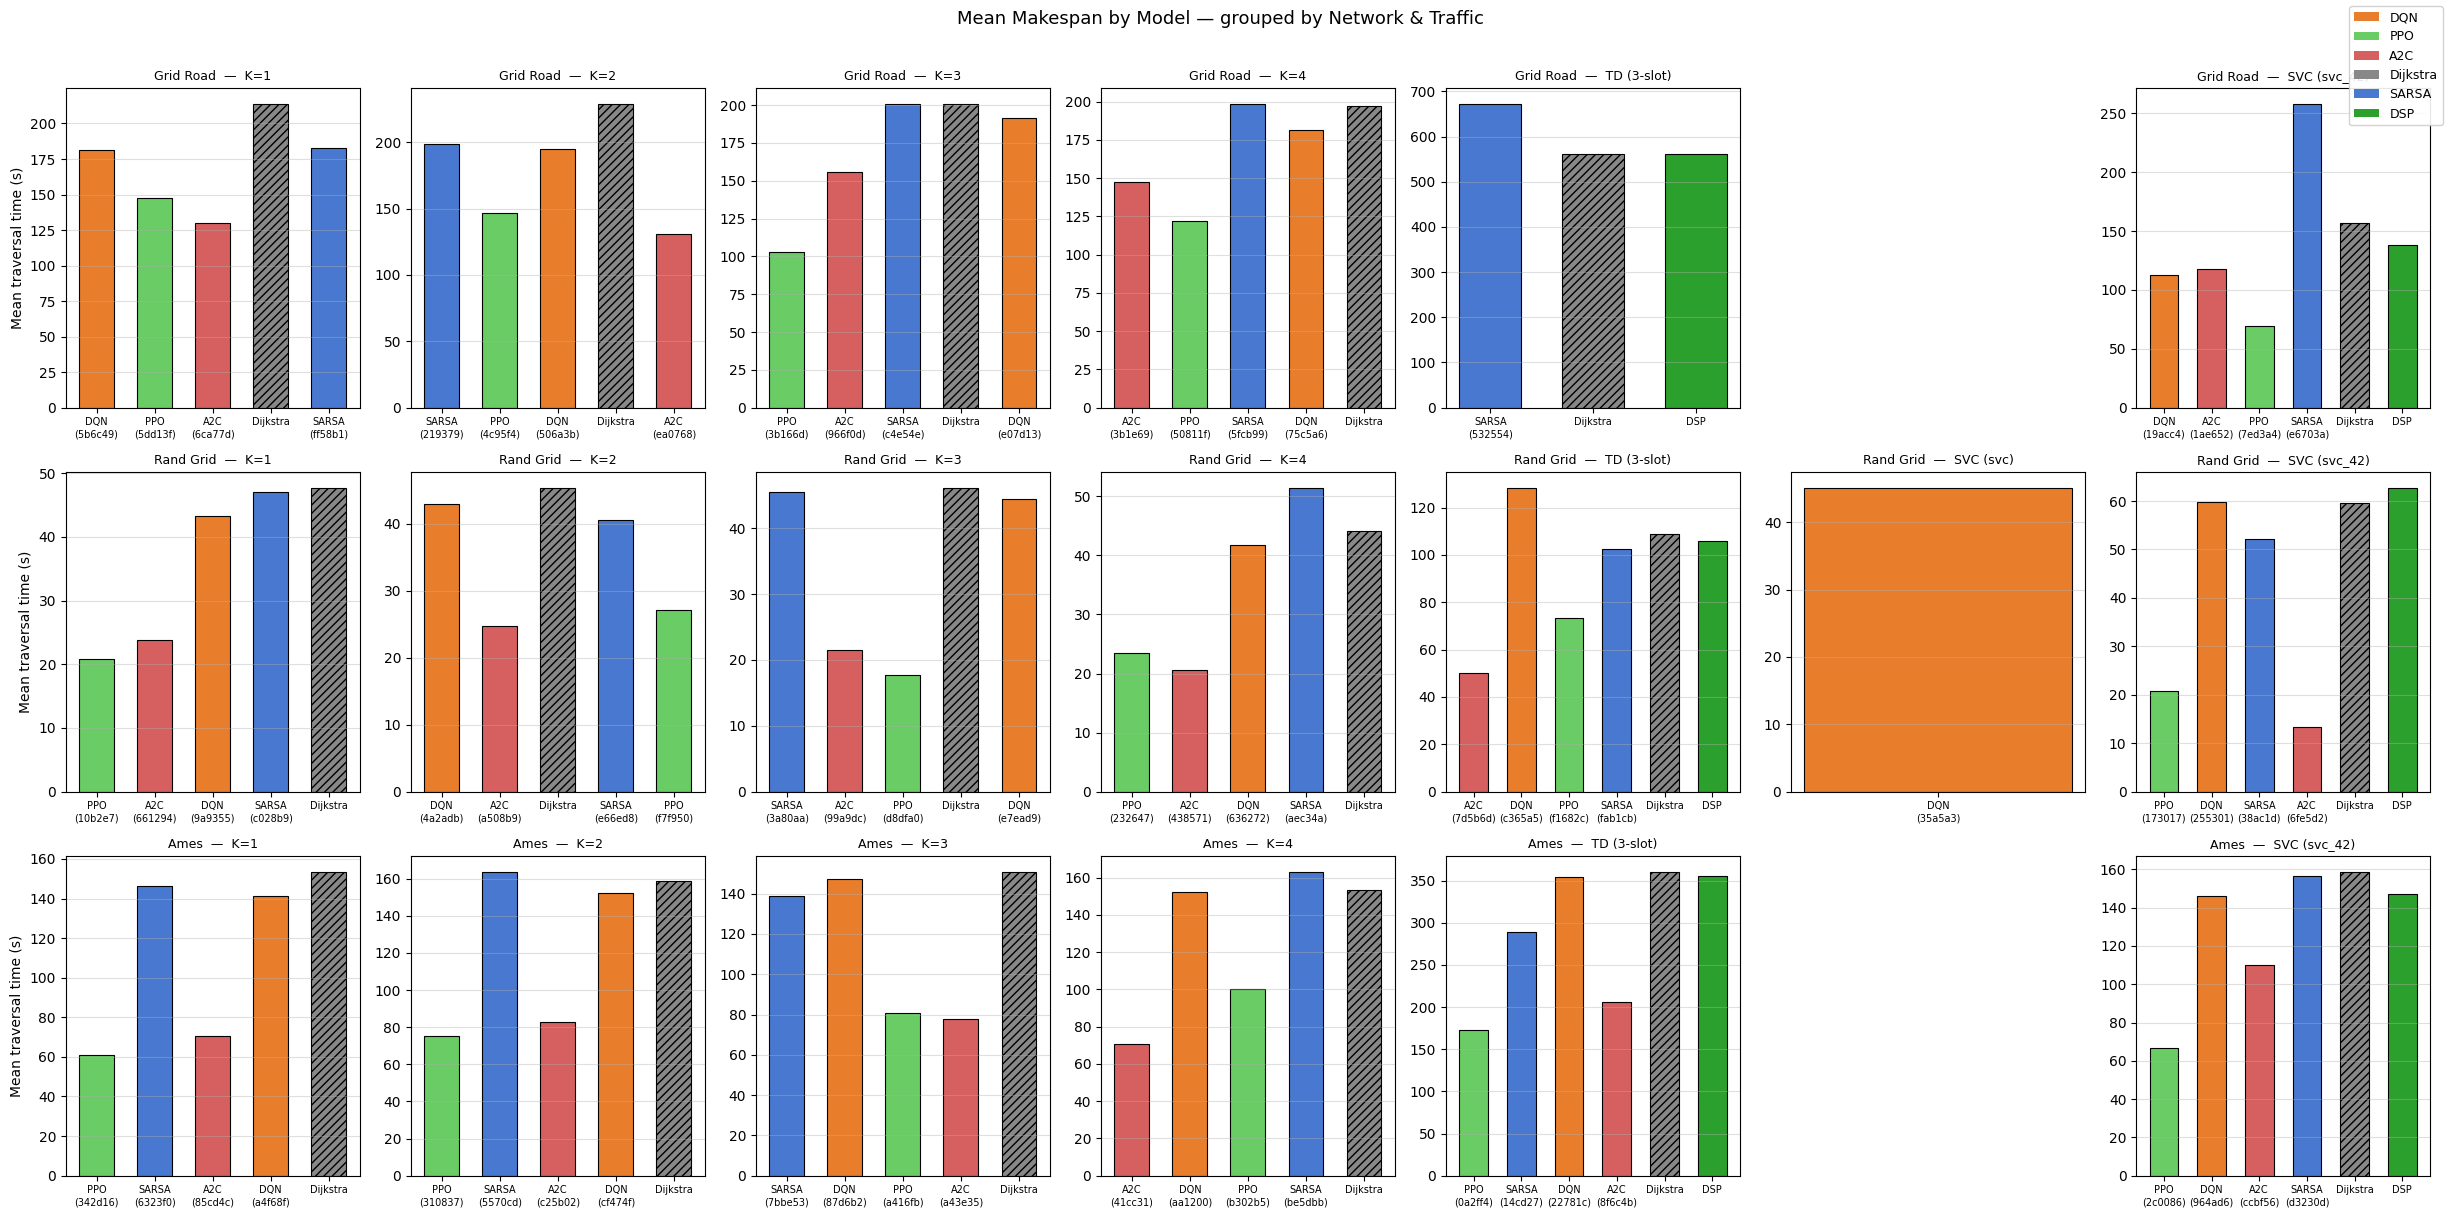

Saved: aggregate_success_rate.png


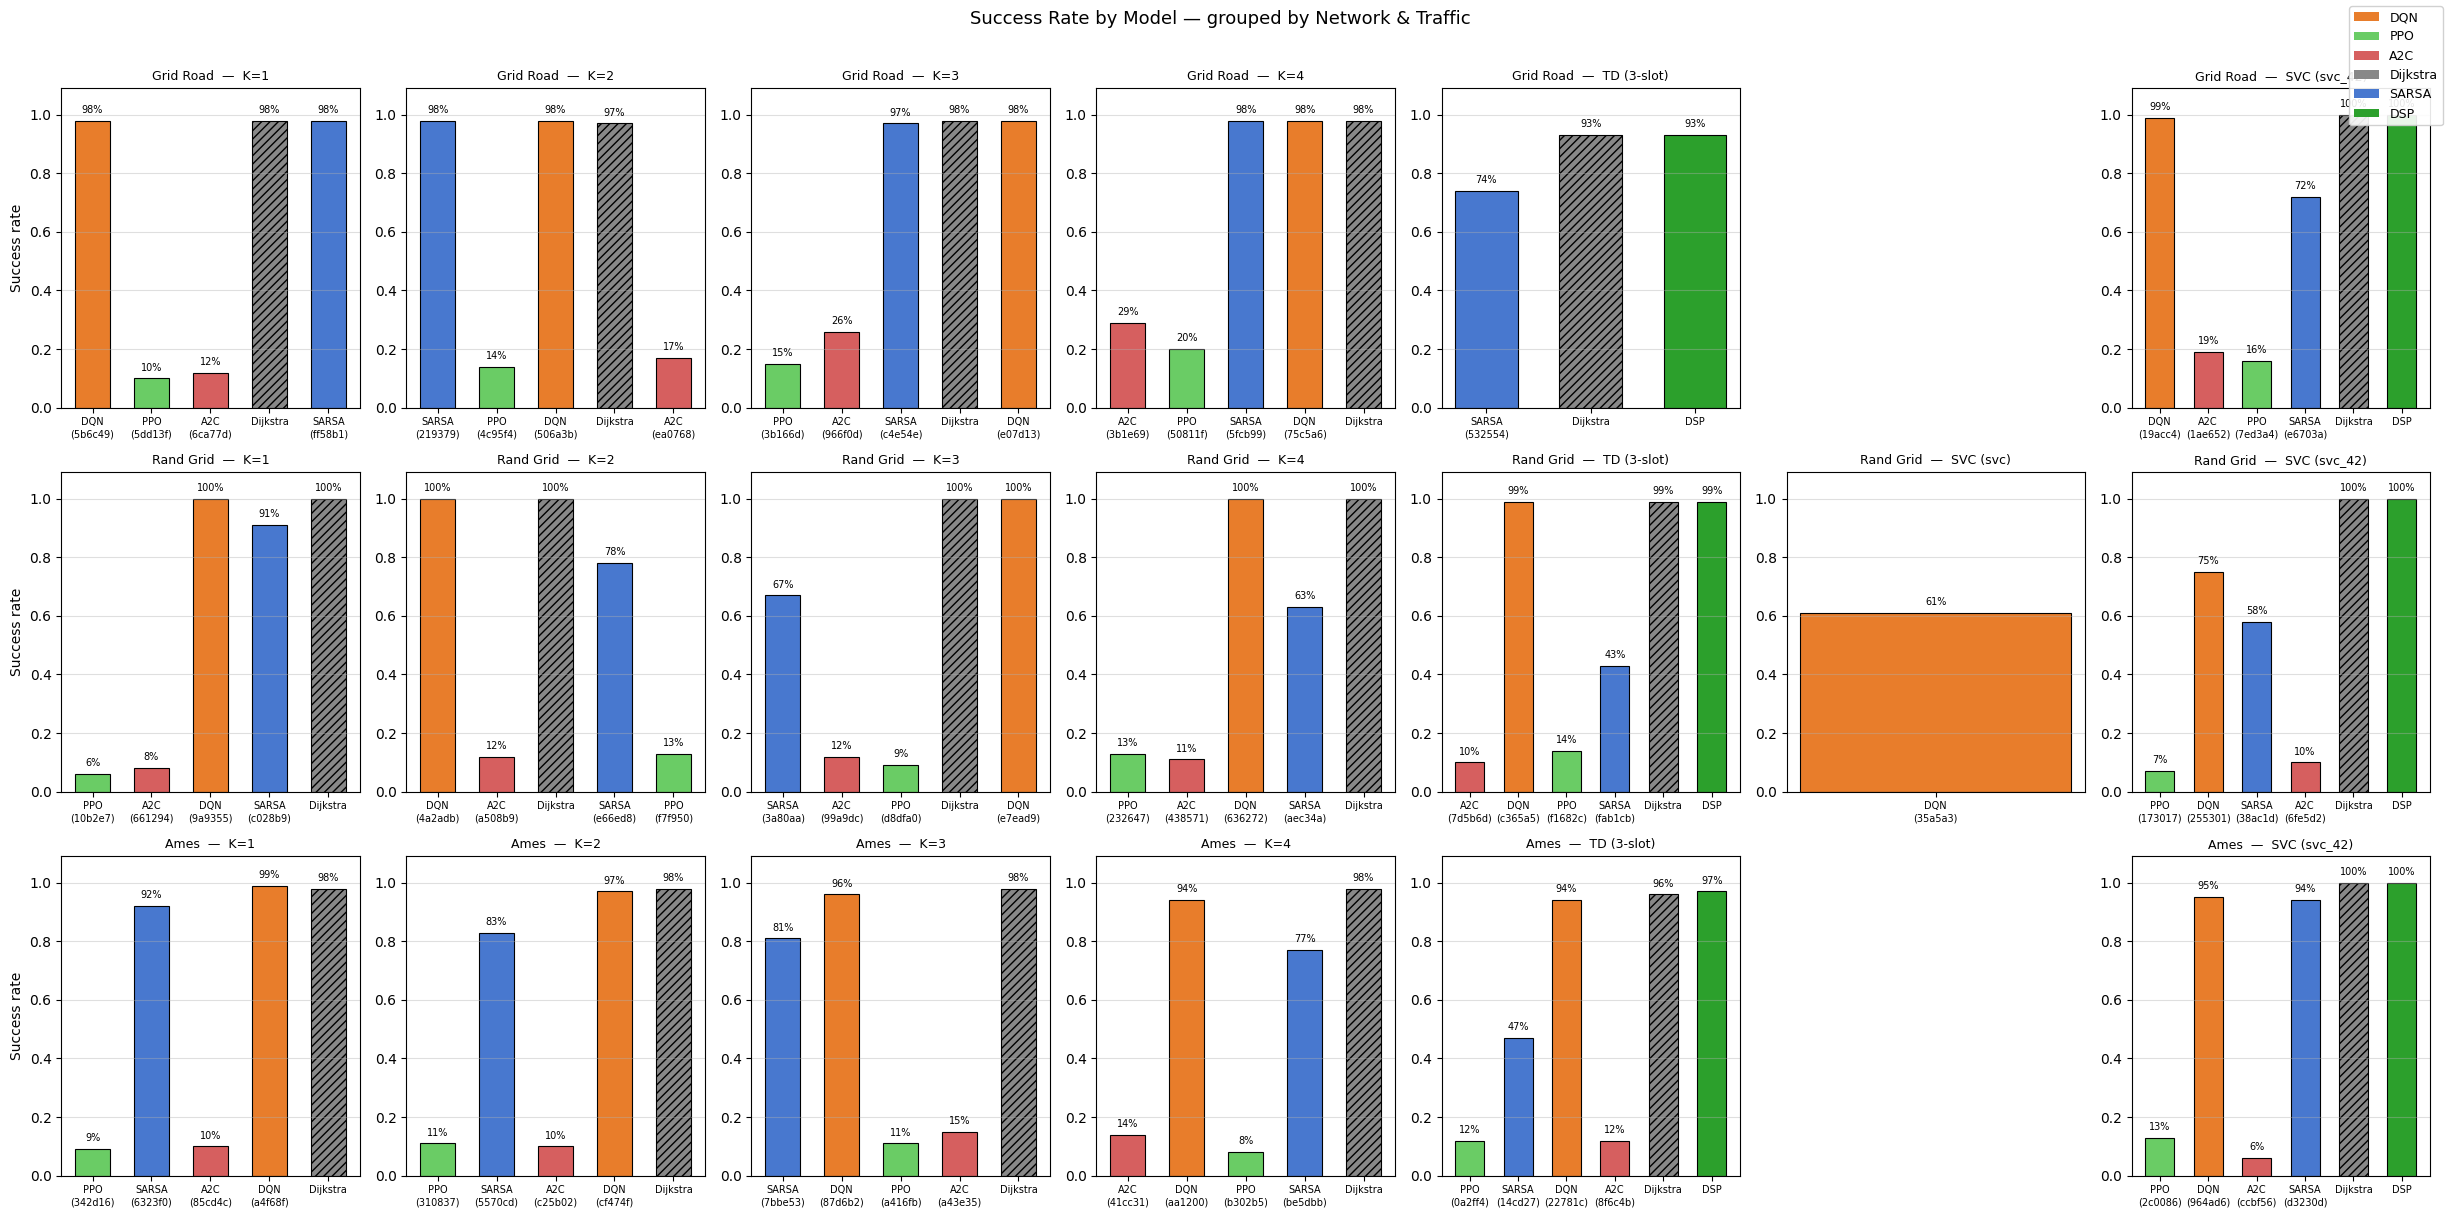

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

model_algo = dict(zip(results_df['model'], results_df['algo']))

# SVC and TD variants share colors with their PSL counterparts so the same
# algorithm reads consistently across traffic columns in the grid.
ALGO_COLORS = {
    'dijkstra':  '#888888', 'dsp':       '#2ca02c',
    'sarsa':     '#4878cf', 'sarsa_svc': '#4878cf',
    'dqn':       '#e87d2b', 'dqn_svc':   '#e87d2b',
    'ppo':       '#6acc65', 'ppo_svc':   '#6acc65',
    'a2c':       '#d65f5f', 'a2c_svc':   '#d65f5f',
}
ALGO_LABELS = {
    'dijkstra':  'Dijkstra', 'dsp':       'DSP',
    'sarsa':     'SARSA',    'sarsa_svc': 'SARSA',
    'dqn':       'DQN',      'dqn_svc':   'DQN',
    'ppo':       'PPO',      'ppo_svc':   'PPO',
    'a2c':       'A2C',      'a2c_svc':   'A2C',
}
NET_LABELS = {'N1': 'Grid Road', 'N2': 'Rand Grid', 'N3': 'Ames'}

def _make_traf_label(tid):
    if tid.startswith('SVC-'):
        return f"SVC ({tid[4:]})"
    if tid == 'TD':
        return 'TD (3-slot)'
    return {'T1': 'K=1', 'T2': 'K=2', 'T3': 'K=3', 'T4': 'K=4'}.get(tid, tid)

NETWORKS = ['N1', 'N2', 'N3']
# PSL slots first (T1..T4), then TD, then SVC conditions (sorted alphabetically)
TRAFFICS = sorted(
    results_df['traffic'].unique(),
    key=lambda t: (not t.startswith('T'), t),
)

def model_display(model):
    algo  = model_algo.get(model, model)
    label = ALGO_LABELS.get(algo, algo.upper())
    if model not in ('dijkstra', 'dsp') and model != algo:
        label += f'\n({model[:6]})'
    return label

_SAVE_DIR = Path('.')
_METRIC_FILENAMES = {
    'makespan_mean': 'aggregate_makespan.png',
    'success_rate':  'aggregate_success_rate.png',
}

for metric, ylabel, title_prefix in [
    ('makespan_mean', 'Mean traversal time (s)', 'Mean Makespan'),
    ('success_rate',  'Success rate',            'Success Rate'),
]:
    present_networks = [n for n in NETWORKS if n in results_df['network'].values]
    n_rows = len(present_networks)
    n_cols = len(TRAFFICS)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(max(4, 3.5 * n_cols), 4 * n_rows),
        sharey=False,
    )
    if n_rows == 1: axes = axes[np.newaxis, :]
    if n_cols == 1: axes = axes[:, np.newaxis]
    fig.suptitle(
        f'{title_prefix} by Model — grouped by Network & Traffic',
        fontsize=13, y=1.01,
    )

    for row_i, nid in enumerate(present_networks):
        for col_i, tid in enumerate(TRAFFICS):
            ax = axes[row_i][col_i]
            subset = results_df[
                (results_df['network'] == nid) & (results_df['traffic'] == tid)
            ].reset_index(drop=True)

            if subset.empty:
                ax.set_visible(False)
                continue

            models  = subset['model'].tolist()
            values  = subset[metric].tolist()
            labels  = [model_display(m) for m in models]
            colors  = [ALGO_COLORS.get(model_algo.get(m, ''), '#aaaaaa') for m in models]
            hatches = ['////' if m == 'dijkstra' else '' for m in models]

            bars = ax.bar(
                range(len(models)), values, color=colors,
                width=0.6, edgecolor='black', linewidth=0.8,
            )
            for bar, hatch in zip(bars, hatches):
                bar.set_hatch(hatch)

            ax.set_xticks(range(len(models)))
            ax.set_xticklabels(labels, fontsize=7)
            ax.set_title(
                f'{NET_LABELS.get(nid, nid)}  —  {_make_traf_label(tid)}',
                fontsize=9,
            )
            ax.set_ylabel(ylabel if col_i == 0 else '')
            ax.grid(axis='y', alpha=0.4)

            if metric == 'success_rate':
                ax.set_ylim(0, 1.09)
                for i, v in enumerate(values):
                    ax.text(i, v + 0.02, f'{v:.0%}',
                            ha='center', va='bottom', fontsize=7)

    # Legend: one entry per unique display label (deduplicates PSL/SVC/TD pairs)
    seen_labels = set()
    legend_patches = []
    for algo in [model_algo.get(m, m) for m in results_df['model'].unique()]:
        lbl = ALGO_LABELS.get(algo, algo.upper())
        if lbl not in seen_labels:
            seen_labels.add(lbl)
            legend_patches.append(
                mpatches.Patch(facecolor=ALGO_COLORS.get(algo, '#aaaaaa'), label=lbl)
            )
    fig.legend(handles=legend_patches, loc='upper right', fontsize=9, framealpha=0.9)
    plt.tight_layout()

    save_path = _SAVE_DIR / _METRIC_FILENAMES[metric]
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Saved: {save_path}")
    plt.show()